# Customer Churn Prediction — Final Data Science Notebook

## 1. Introduction and objectives

Customer churn is the loss of active subscribers and can reduce recurring
revenue while increasing replacement costs. The business problem is to identify
customers at elevated risk early enough to prioritize limited retention capacity.
Machine learning is appropriate because risk can depend on nonlinear combinations
of service, usage, payment, contract, and experience signals.

This notebook integrates the validated outputs of Phases 1–8 into one
reproducible, leakage-safe workflow. Its objectives are to audit the cleaned data,
explain preprocessing and engineered features, compare candidate models, verify
the checksum-locked final model on the untouched test split, explain its behavior,
and translate score rankings into a capacity-constrained retention scenario.

**Governance boundary:** this is retrospective decision support, not a causal
impact study. Customer identifiers are excluded from predictors and outputs.

## 2. Imports, configuration, and package versions

In [1]:
from pathlib import Path
import json, platform, sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").is_dir() and (PROJECT_ROOT.parent / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from src.evaluation import compute_classification_metrics, positive_class_probabilities, predictions_at_threshold
from src.explainability import load_trusted_locked_model
from src.feature_engineering import CustomerFeatureEngineer
from src.preprocessing import dataframe_fingerprint, separate_features_target_ids
from src.retention_simulation import (
    build_internal_analysis_table, calculate_selection_metrics,
    cumulative_gains_data, exact_random_selection_expectations,
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (8, 4.5), "figure.dpi": 110})

print({
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scikit_learn": sklearn.__version__,
})

{'python': '3.13.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scikit_learn': '1.9.1'}


## 3. Data and artifact loading

In [2]:
ROOT = PROJECT_ROOT

def first_existing(*relative_paths):
    for relative in relative_paths:
        candidate = ROOT / relative
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Required artifact not found; checked: {relative_paths}")

DATA_PATH = first_existing("data/processed/02_cleaned_dataset.csv", "02_cleaned_dataset.csv")
MODEL_PATH = first_existing("models/03_model_artifact.joblib", "03_model_artifact.joblib")
SPLIT_PATH = first_existing("data/processed/02_split_indices.json", "support/results/02_split_indices.json")
METADATA_PATH = first_existing("models/final_model_metadata.json", "support/results/final_model_metadata.json")

data = pd.read_csv(DATA_PATH)
split_payload = json.loads(SPLIT_PATH.read_text(encoding="utf-8"))
metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
print(f"Loaded {data.shape[0]:,} rows and {data.shape[1]} columns.")
print("Dataset fingerprint:", dataframe_fingerprint(data))

Loaded 1,200 rows and 20 columns.
Dataset fingerprint: df788deba598b73abdc3a41b8a1947af63a90c5f369c2a498386a2c0eefeb769


## 4. Initial data audit

The audit checks shape, types, missingness, duplicates, numeric ranges,
outlier candidates, and class balance. Identifier values are intentionally
never displayed.

,dtype,missing_count,missing_percent,unique_values
age,int64,0,0.0,58
tenure_months,int64,0,0.0,72
contract_type,str,0,0.0,3
internet_service,str,0,0.0,3
region,str,0,0.0,9
monthly_charges,float64,30,2.5,1067
total_charges,float64,24,2.0,1176
payment_method,str,0,0.0,4
paperless_billing,str,0,0.0,2
dependents,str,0,0.0,2


Duplicate full rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1200.0,NaN,NaN,NaN,46.746667,16.666702,18.0,32.0,47.0,61.0,75.0
tenure_months,1200.0,NaN,NaN,NaN,36.265833,20.917372,1.0,18.0,35.0,54.0,72.0
contract_type,1200,3,Month-to-month,708,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_service,1200,3,Fiber optic,621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1200,9,Western,147,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_charges,1170.0,NaN,NaN,NaN,71.429769,25.823951,20.0,54.445,71.82,86.995,235.01
total_charges,1176.0,NaN,NaN,NaN,2568.007194,1807.259488,22.73,1119.23,2244.46,3752.0275,8853.76
payment_method,1200,4,Electronic check,392,NaN,NaN,NaN,NaN,NaN,NaN,NaN
paperless_billing,1200,2,Yes,784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,1200,2,No,840,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,IQR outlier candidates
senior_citizen,206
late_payments_last_12m,57
complaints_last_12m,41
total_charges,14
monthly_charges,12
monthly_usage_gb,5
satisfaction_score,4
discount_pct,2
tenure_months,0
age,0


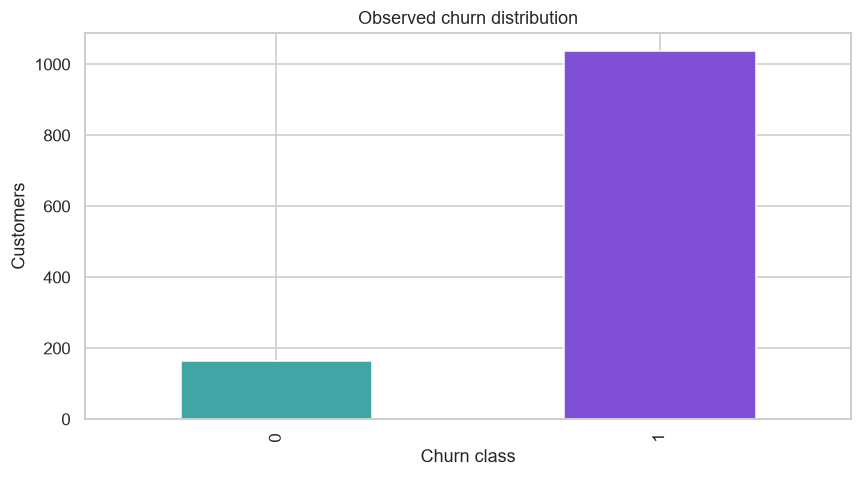

In [3]:
public_data = data.drop(columns=["customer_id"], errors="ignore")
audit = pd.DataFrame({
    "dtype": public_data.dtypes.astype(str),
    "missing_count": public_data.isna().sum(),
    "missing_percent": public_data.isna().mean().mul(100).round(2),
    "unique_values": public_data.nunique(dropna=True),
})
display(audit)
print("Duplicate full rows:", int(data.duplicated().sum()))
display(public_data.describe(include="all").transpose().round(3))

numeric = public_data.select_dtypes(include="number").drop(columns=["churn"], errors="ignore")
q1, q3 = numeric.quantile(.25), numeric.quantile(.75)
iqr = q3 - q1
outlier_counts = ((numeric.lt(q1 - 1.5 * iqr)) | (numeric.gt(q3 + 1.5 * iqr))).sum()
display(outlier_counts.rename("IQR outlier candidates").sort_values(ascending=False).to_frame())

ax = public_data["churn"].value_counts().sort_index().plot.bar(color=["#42A5A5", "#8051D6"])
ax.set(title="Observed churn distribution", xlabel="Churn class", ylabel="Customers")
plt.tight_layout(); plt.show()

## 5. Cleaning, preprocessing, and leakage-safe split

Phase 2 standardized data types and validated domain rules without dropping
rows. A fingerprint-bound, stratified 80/20 split (random state 42) was saved
before modeling. Missing-value imputation, scaling, one-hot encoding, and all
learned transformations live inside the model pipeline and are fitted only on
training folds. `customer_id` and `churn` are explicitly excluded from inputs.

In [4]:
X, y, _identifiers = separate_features_target_ids(data)
train_idx = np.asarray(split_payload["train_indices"], dtype=int)
test_idx = np.asarray(split_payload["test_indices"], dtype=int)
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_test)],
    "churn_rate": [y_train.mean(), y_test.mean()],
    "predictor_columns": [X_train.shape[1], X_test.shape[1]],
}, index=["training", "held-out test"])
display(split_summary.round(4))
assert not ({"customer_id", "churn"} & set(X.columns))
assert not (set(train_idx) & set(test_idx))
assert set(train_idx) | set(test_idx) == set(range(len(data)))
print("Leakage checks passed; EDA below uses training rows only.")

,rows,churn_rate,predictor_columns
training,960,0.8635,18
held-out test,240,0.8625,18


Leakage checks passed; EDA below uses training rows only.


## 6. Exploratory data analysis

The following nine panels use only the training partition and cover the main
behavioral, service, financial, and demographic relationships assessed in
the project. Associations are descriptive and should not be read as causal.

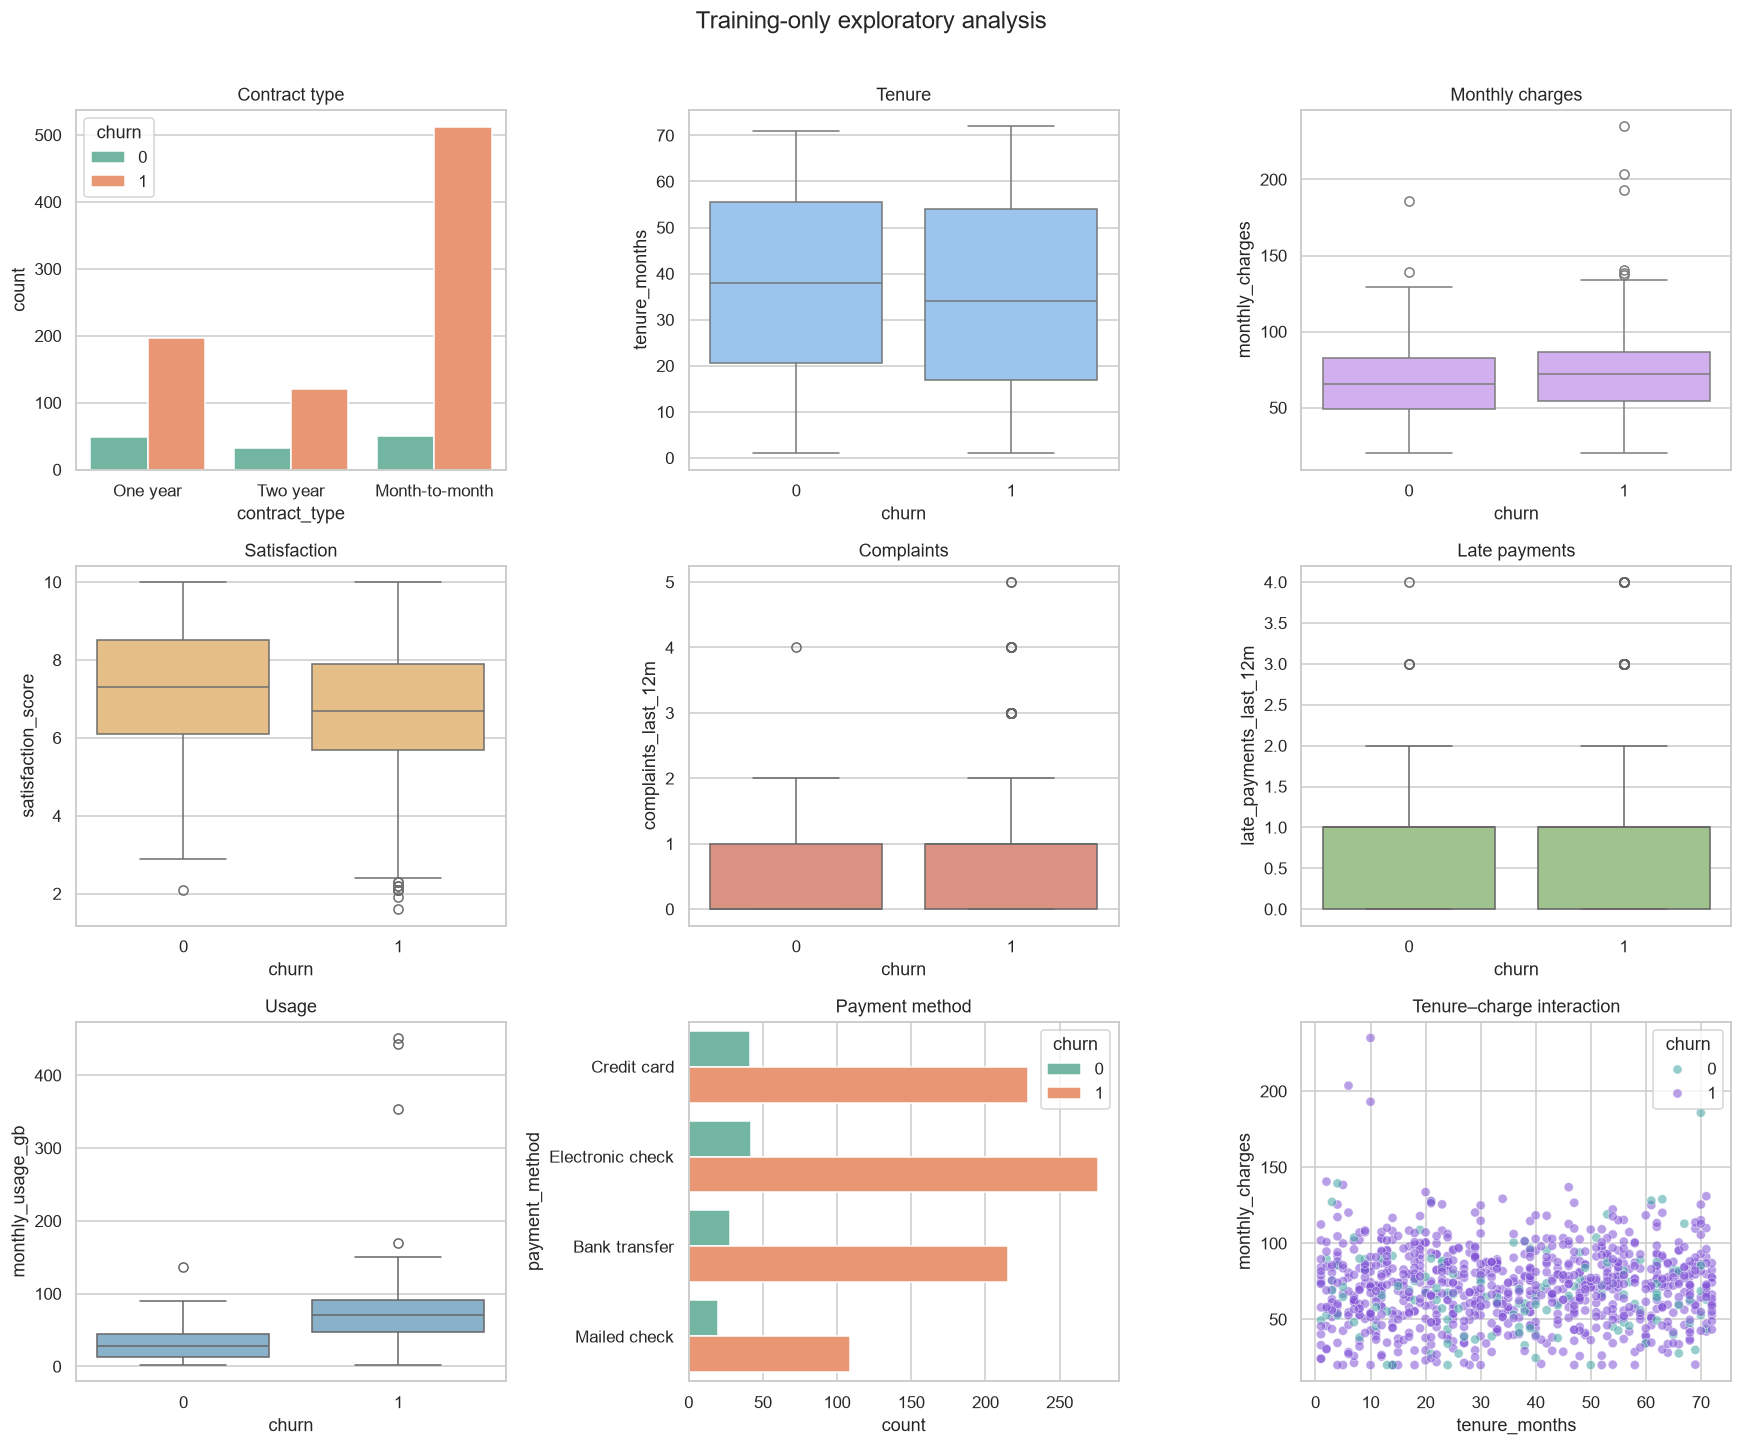

In [5]:
eda = X_train.copy(); eda["churn"] = y_train.to_numpy()
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
sns.countplot(data=eda, x="contract_type", hue="churn", ax=axes[0,0], palette="Set2")
sns.boxplot(data=eda, x="churn", y="tenure_months", ax=axes[0,1], color="#8EC5FC")
sns.boxplot(data=eda, x="churn", y="monthly_charges", ax=axes[0,2], color="#D3A4F9")
sns.boxplot(data=eda, x="churn", y="satisfaction_score", ax=axes[1,0], color="#F6C177")
sns.boxplot(data=eda, x="churn", y="complaints_last_12m", ax=axes[1,1], color="#E98973")
sns.boxplot(data=eda, x="churn", y="late_payments_last_12m", ax=axes[1,2], color="#9CCB86")
sns.boxplot(data=eda, x="churn", y="monthly_usage_gb", ax=axes[2,0], color="#7FB3D5")
sns.countplot(data=eda, y="payment_method", hue="churn", ax=axes[2,1], palette="Set2")
sns.scatterplot(data=eda, x="tenure_months", y="monthly_charges", hue="churn",
                alpha=.55, ax=axes[2,2], palette={0:"#42A5A5", 1:"#8051D6"})
titles = ["Contract type", "Tenure", "Monthly charges", "Satisfaction",
          "Complaints", "Late payments", "Usage", "Payment method",
          "Tenure–charge interaction"]
for ax, title in zip(axes.flat, titles): ax.set_title(title)
fig.suptitle("Training-only exploratory analysis", fontsize=16, y=1.01)
plt.tight_layout(); plt.show()

## 7. Feature engineering

Seven deterministic, interpretable features are created inside every fit/resample
operation:

- `tenure_years`: converts tenure into a business-friendly time scale.
- `complaints_per_active_month`: normalizes complaints for customer exposure time.
- `payment_risk_score`: combines late-payment frequency and payment friction.
- `complaint_satisfaction_interaction`: captures compounding experience risk.
- `monthly_contract_tenure`: represents recurring value accumulated over tenure.
- `late_payment_charge_interaction`: represents financial exposure with lateness.
- `usage_per_charge`: approximates perceived usage value per monetary unit.

All use predictor-time information only; neither the target nor identifier is used.

In [6]:
engineer = CustomerFeatureEngineer()
engineered_train = engineer.fit_transform(X_train)
engineered_names = [name for name in engineered_train.columns if name not in X_train.columns]
display(engineered_train[engineered_names].describe().transpose().round(3))
print("Engineered features:", ", ".join(engineered_names))

,count,mean,std,min,25%,50%,75%,max
tenure_years,960.0,2.988,1.761,0.083,1.500,2.917,4.500,6.000
complaints_per_active_month,960.0,0.078,0.155,0.000,0.000,0.083,0.083,2.000
payment_risk_score,960.0,1.524,1.261,0.000,1.000,1.000,2.000,8.000
complaint_satisfaction_interaction,922.0,2.244,3.311,0.000,0.000,0.000,3.700,23.700
monthly_contract_tenure,960.0,21.528,24.315,0.000,0.000,11.000,42.250,72.000
late_payment_charge_interaction,932.0,59.210,70.558,0.000,0.000,48.615,88.795,451.760
usage_per_charge,910.0,1.078,0.853,0.017,0.572,0.942,1.353,7.757


Engineered features: tenure_years, complaints_per_active_month, payment_risk_score, complaint_satisfaction_interaction, monthly_contract_tenure, late_payment_charge_interaction, usage_per_charge


## 8. Model development and hyperparameter tuning

Phase 5 compared a naive prior baseline, logistic regression, random forest,
and histogram gradient boosting with five-fold stratified cross-validation.
Average precision was primary because churn is prevalent and the business use
case ranks customers. Tuning and model selection used training data only; this
final notebook reuses the saved results instead of rerunning expensive searches.

In [7]:
comparison_path = first_existing("reports/modeling/phase5_model_comparison.csv", "support/results/phase5_model_comparison.csv")
comparison = pd.read_csv(comparison_path)
display(comparison.loc[comparison["stage"].isin(["Naive reference", "Tuned"]),
                       ["model", "stage", "mean_pr_auc", "std_pr_auc", "mean_roc_auc", "mean_precision_at_20"]]
        .sort_values("mean_pr_auc", ascending=False).round(4))
print("Selected model: tuned random forest with class_weight='balanced'.")

,model,stage,mean_pr_auc,std_pr_auc,mean_roc_auc,mean_precision_at_20
4,Random Forest,Tuned,0.9782,0.0060,0.8822,0.9949
2,Logistic Regression,Tuned,0.9752,0.0151,0.8816,0.9897
6,Histogram Gradient Boosting,Tuned,0.9741,0.0054,0.8715,0.9949
0,Naive Prior Baseline,Naive reference,0.8635,0.0023,0.5000,0.8718


Selected model: tuned random forest with class_weight='balanced'.


## 9. Class imbalance, calibration, and operating policy

In [8]:
weight_path = first_existing("reports/modeling/phase5_class_weight_comparison.csv", "support/results/phase5_class_weight_comparison.csv")
calibration_path = first_existing("reports/evaluation/phase6_calibration_comparison.csv", "support/results/phase6_calibration_comparison.csv")
display(pd.read_csv(weight_path)[["model", "class_weight", "mean_pr_auc", "mean_roc_auc", "mean_precision_at_20"]].round(4))
display(pd.read_csv(calibration_path)[["method", "brier_score", "log_loss", "average_precision", "expected_calibration_error"]].round(4))
print(f"Locked calibration: {metadata['calibration']['method']}; operating threshold: {metadata['operating_threshold']:.12f}")
print("The threshold was selected from training-only out-of-fold probabilities, before the test set was evaluated.")

threshold_path = first_existing("reports/evaluation/phase6_threshold_key_points.csv", "support/results/phase6_threshold_key_points.csv")
display(pd.read_csv(threshold_path).round(4))

,model,class_weight,mean_pr_auc,mean_roc_auc,mean_precision_at_20
0,Logistic Regression,NaN,0.9711,0.8653,0.9846
1,Logistic Regression,balanced,0.9709,0.8654,0.9795
2,Random Forest,NaN,0.9706,0.8575,0.9897
3,Random Forest,balanced,0.9732,0.8701,0.9846
4,Histogram Gradient Boosting,NaN,0.9699,0.8606,0.9795
5,Histogram Gradient Boosting,balanced,0.9686,0.8636,0.9795


,method,brier_score,log_loss,average_precision,expected_calibration_error
0,uncalibrated,0.1061,0.3328,0.9773,0.1181
1,sigmoid,0.0840,0.2752,0.9782,0.0219
2,isotonic,0.0845,0.3078,0.9736,0.0129


Locked calibration: sigmoid; operating threshold: 0.970709000432
The threshold was selected from training-only out-of-fold probabilities, before the test set was evaluated.


,threshold,predicted_positive_count,predicted_positive_rate,precision,recall,f1,false_positive,false_negative,true_positive,true_negative
0,0.1000,960,1.0000,0.8635,1.0000,0.9268,131,0,829,0
1,0.2000,960,1.0000,0.8635,1.0000,0.9268,131,0,829,0
2,0.3000,958,0.9979,0.8653,1.0000,0.9278,129,0,829,2
3,0.4000,941,0.9802,0.8767,0.9952,0.9322,116,4,825,15
4,0.5000,899,0.9365,0.8999,0.9759,0.9363,90,20,809,41
5,0.6000,865,0.9010,0.9121,0.9517,0.9315,76,40,789,55
6,0.7000,812,0.8458,0.9323,0.9131,0.9226,55,72,757,76
7,0.8000,735,0.7656,0.9510,0.8432,0.8939,36,130,699,95
8,0.9000,609,0.6344,0.9770,0.7177,0.8275,14,234,595,117
9,0.9707,192,0.2000,0.9948,0.2304,0.3741,1,638,191,130


## 10. Locked final-model verification and evaluation

In [9]:
locked_model = load_trusted_locked_model(
    MODEL_PATH, expected_sha256=metadata["model_artifact_sha256"], trusted=True
)
probabilities = positive_class_probabilities(locked_model, X_test)
threshold = float(metadata["operating_threshold"])
predictions = predictions_at_threshold(probabilities, threshold)
measured = compute_classification_metrics(y_test, probabilities, threshold=threshold)
display(pd.Series(measured, name="held-out value").to_frame().round(6))

stored_path = first_existing("reports/evaluation/phase6_final_test_metrics.json", "support/results/phase6_final_test_metrics.json")
stored = json.loads(stored_path.read_text(encoding="utf-8"))["selected_business_threshold"]
for key in ("accuracy", "precision", "recall", "f1", "roc_auc", "average_precision", "brier_score", "log_loss"):
    assert np.isclose(measured[key], stored[key], atol=1e-12)
print("Locked held-out metrics reproduce exactly within numerical tolerance.")

robustness_path = first_existing("reports/evaluation/phase6_cv_robustness.csv", "support/results/phase6_cv_robustness.csv")
print("Training-CV robustness summary:")
display(pd.read_csv(robustness_path).round(4))

,held-out value
threshold,0.970709
observations,240.000000
predicted_positive_count,99.000000
predicted_positive_rate,0.412500
accuracy,0.541667
precision,0.989899
recall,0.473430
f1,0.640523
roc_auc,0.899429
average_precision,0.981852


Locked held-out metrics reproduce exactly within numerical tolerance.
Training-CV robustness summary:


,metric,mean,standard_deviation,minimum,maximum,folds
0,precision,0.9451,0.0172,0.9268,0.9724,5
1,recall,0.8626,0.0340,0.8373,0.9212,5
2,roc_auc,0.8822,0.0229,0.8582,0.9096,5
3,pr_auc,0.9782,0.0060,0.9716,0.9855,5


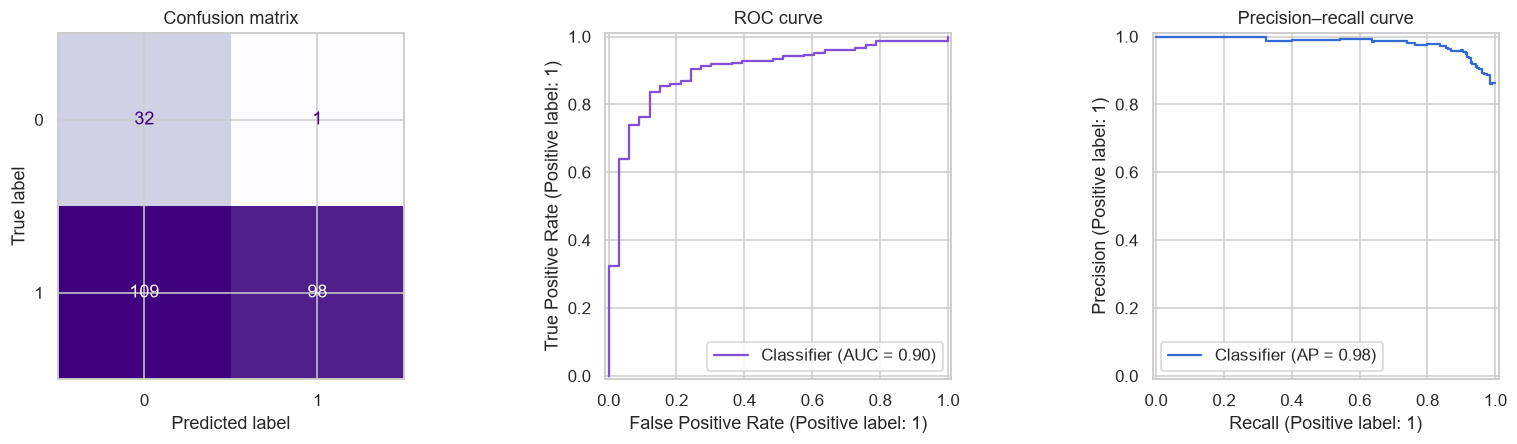

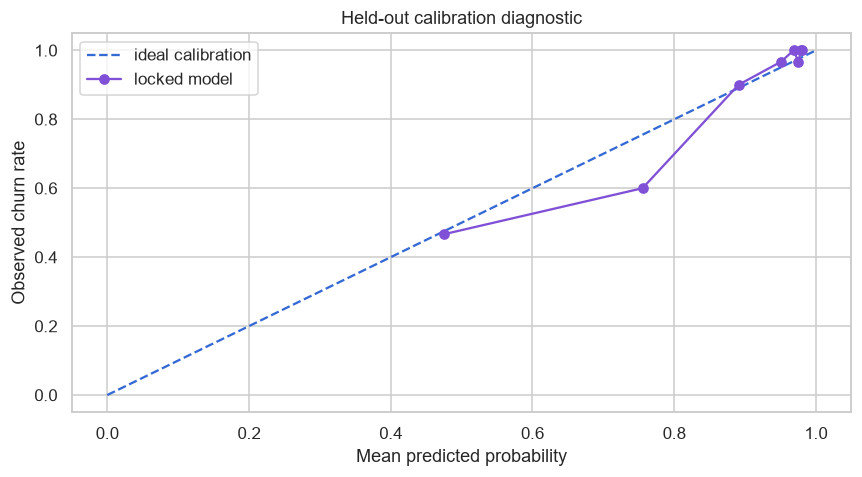

In [10]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Purples", ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], curve_kwargs={"color": "#8051D6"})
PrecisionRecallDisplay.from_predictions(y_test, probabilities, ax=axes[2], curve_kwargs={"color": "#3569D4"})
axes[0].set_title("Confusion matrix"); axes[1].set_title("ROC curve"); axes[2].set_title("Precision–recall curve")
plt.tight_layout(); plt.show()

observed, predicted = calibration_curve(y_test, probabilities, n_bins=8, strategy="quantile")
plt.plot([0,1], [0,1], "--", color="#3569D4", label="ideal calibration")
plt.plot(predicted, observed, marker="o", color="#8051D6", label="locked model")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed churn rate")
plt.title("Held-out calibration diagnostic"); plt.legend(); plt.tight_layout(); plt.show()

## 11. Model explainability and customer-level risk analysis

Permutation importance measures held-out predictive dependence—not causality.
Local cases are anonymized. Probability sensitivity helps explain model behavior
but should not be interpreted as an intervention effect.

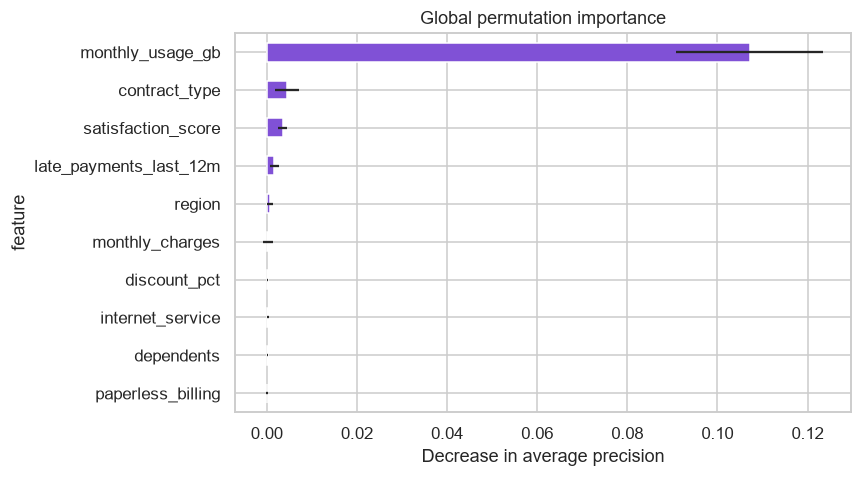

,customer_label,actual_churn,predicted_probability,threshold,predicted_class,correct_prediction,confusion_category,monthly_usage_gb,contract_type,satisfaction_score,late_payments_last_12m,region,monthly_charges,discount_pct,internet_service
0,Customer A,1,0.9783,0.9707,1,True,true_positive,75.8,Month-to-month,7.2,1,Central,46.63,1.79,DSL
1,Customer B,0,0.6423,0.9707,0,True,true_negative,35.4,One year,6.7,2,Sabaragamuwa,Missing,13.36,Fiber optic
2,Customer C,1,0.9706,0.9707,0,False,false_negative,76.3,One year,7.5,1,North Central,116.07,13.60,DSL


In [11]:
importance_path = first_existing("reports/explainability/phase7_global_permutation_importance.csv", "support/results/phase7_global_permutation_importance.csv")
cases_path = first_existing("reports/explainability/phase7_selected_customers.csv", "support/results/phase7_selected_customers.csv")
importance = pd.read_csv(importance_path).head(10).sort_values("importance_mean")
importance.plot.barh(x="feature", y="importance_mean", xerr="importance_std", legend=False, color="#8051D6")
plt.xlabel("Decrease in average precision"); plt.title("Global permutation importance")
plt.tight_layout(); plt.show()
cases = pd.read_csv(cases_path)
safe_columns = [c for c in cases.columns if c not in {"customer_id", "internal_row_reference"}]
display(cases[safe_columns].round(4))

## 12. Retention intervention simulation and business impact

A strict top-20% capacity policy selects exactly 48 of 240 held-out customers
by score alone. Outcomes are attached only after ranking for retrospective
measurement. Financial values below are scenarios, not realized savings.

,model ranked,random expectation
churners captured,48.0000,41.4000
precision,1.0000,0.8625
recall,0.2319,0.2000
lift,1.1594,1.0000


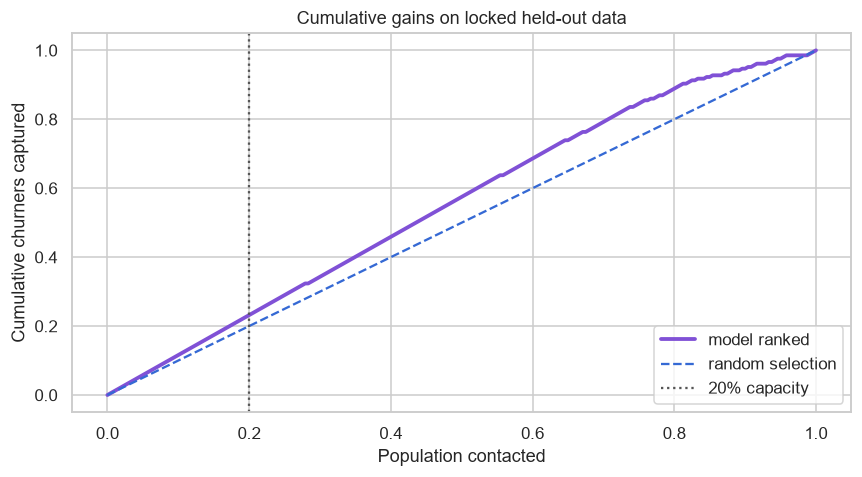

,model ranked,random expectation
expected retained customers,4.8,4.14
expected net benefit ($),480.0,381.00


Sensitivity range across 27 hypothetical cost, value, and effectiveness scenarios:


,incremental_expected_net_benefit,model_expected_net_benefit,random_expected_net_benefit
min,24.75,-300.0,-324.75
median,99.00,480.0,381.00
max,396.00,2784.0,2388.00


In [12]:
analysis = build_internal_analysis_table(probabilities, y_test, predictions, contact_fraction=.20)
selection = calculate_selection_metrics(analysis["actual_churn"], analysis["selected_top_20pct"])
random_expected = exact_random_selection_expectations(
    selection["total_customers"], selection["selected_customers"], selection["total_actual_churners"]
)
display(pd.DataFrame({
    "model ranked": [selection["selected_churners"], selection["precision_at_20"], selection["recall_at_20"], selection["lift_at_20"]],
    "random expectation": [random_expected["expected_churners_captured"], random_expected["expected_random_precision"], random_expected["expected_random_recall"], random_expected["expected_random_lift"]],
}, index=["churners captured", "precision", "recall", "lift"]).round(4))

gains = cumulative_gains_data(y_test, probabilities)
plt.plot(gains["selected_fraction"], gains["model_capture_rate"], color="#8051D6", linewidth=2.5, label="model ranked")
plt.plot([0,1], [0,1], "--", color="#3569D4", label="random selection")
plt.axvline(.20, color="#555555", linestyle=":", label="20% capacity")
plt.xlabel("Population contacted"); plt.ylabel("Cumulative churners captured")
plt.title("Cumulative gains on locked held-out data"); plt.legend(); plt.tight_layout(); plt.show()

retained_model = selection["selected_churners"] * .10
retained_random = random_expected["expected_churners_captured"] * .10
economics = pd.DataFrame({
    "model ranked": [retained_model, retained_model * 150 - 48 * 5],
    "random expectation": [retained_random, retained_random * 150 - 48 * 5],
}, index=["expected retained customers", "expected net benefit ($)"])
display(economics.round(2))

sensitivity_path = first_existing("reports/retention_sensitivity_analysis.csv", "support/results/retention_sensitivity_analysis.csv")
sensitivity = pd.read_csv(sensitivity_path)
print("Sensitivity range across 27 hypothetical cost, value, and effectiveness scenarios:")
display(sensitivity[["incremental_expected_net_benefit", "model_expected_net_benefit", "random_expected_net_benefit"]]
        .agg(["min", "median", "max"]).round(2))

## 13. Business recommendations

The main evidence is strong ranking performance, usage-dominant model dependence,
service/experience associations, and a retrospective top-20% lift of about 1.16.

1. Pilot the score-ranked top-20% contact policy with a randomized holdout group.
2. Prioritize service/usage diagnosis and customer experience rather than treating
   model importance as proof that a specific action will work.
3. Track contact cost, realized retention, incremental value, capacity, calibration,
   and subgroup outcomes before scaling.
4. Revalidate data schema, missingness, score drift, and performance on a regular cadence.
5. Require human review, lawful use, access controls, and an audit trail for outreach.

## 14. Conclusion

The locked calibrated random-forest pipeline is reproducible and strong at ranking
churn risk (held-out ROC-AUC ≈ 0.899; average precision ≈ 0.982). Its high operating
threshold favors precision (≈ 0.990) over recall (≈ 0.473). Under the separate strict
top-20% campaign rule, all 48 contacted held-out customers were churners, compared with
41.4 expected under random selection. These are retrospective results. A controlled
pilot is required to estimate causal retention lift and realized financial return.
Future work should add temporal/out-of-time validation, drift monitoring, subgroup
review, and experiment-based uplift or treatment-effect modeling.